In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Cargar el dataset limpio desde la capa interim
df = pd.read_parquet('../data/interim/mibici_cleaned.parquet')

print(f"Dataset cargado con {df.shape[0]} registros y {df.shape[1]} columnas.")
df.head()

Dataset cargado con 38990791 registros y 8 columnas.


,viaje_id,usuario_id,genero,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,anio_nacimiento
0,4628,3,F,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79,1990.0
1,4631,102,M,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79,1982.0
2,4632,3,F,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79,1990.0
3,4636,3,F,2014-12-01 09:50:13,2014-12-01 09:50:18,79,79,1990.0
4,4637,102,M,2014-12-01 09:49:05,2014-12-01 09:49:17,79,79,1982.0


In [3]:
# Extraer componentes de la fecha de inicio del viaje
df['hora'] = df['inicio_del_viaje'].dt.hour
df['dia_semana'] = df['inicio_del_viaje'].dt.dayofweek # 0=Lunes, 6=Domingo
df['mes'] = df['inicio_del_viaje'].dt.month
df['es_fin_de_semana'] = df['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

print("Nuevas características temporales creadas.")

C:\Users\alejandro.ojedaz\AppData\Local\Temp\ipykernel_42476\907349006.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = df['inicio_del_viaje'].dt.dayofweek # 0=Lunes, 6=Domingo


Nuevas características temporales creadas.


In [4]:
df.head()

,viaje_id,usuario_id,genero,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,anio_nacimiento,hora,dia_semana,mes,es_fin_de_semana
0,4628,3,F,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79,1990.0,9,0,12,0
1,4631,102,M,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79,1982.0,9,0,12,0
2,4632,3,F,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79,1990.0,9,0,12,0
3,4636,3,F,2014-12-01 09:50:13,2014-12-01 09:50:18,79,79,1990.0,9,0,12,0
4,4637,102,M,2014-12-01 09:49:05,2014-12-01 09:49:17,79,79,1982.0,9,0,12,0


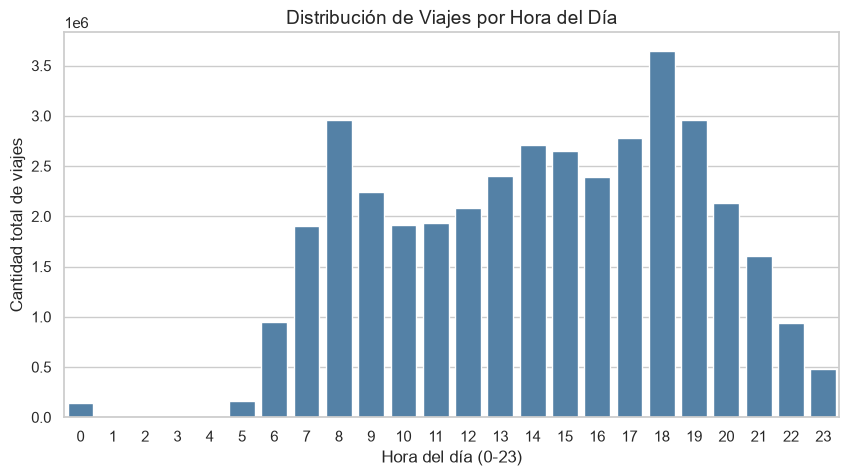

In [5]:
# Agrupar por hora y contar el número de viajes
viajes_por_hora = df.groupby('hora').size()

plt.figure(figsize=(10, 5))
sns.barplot(x=viajes_por_hora.index, y=viajes_por_hora.values, color='steelblue')
plt.title('Distribución de Viajes por Hora del Día', fontsize=14)
plt.xlabel('Hora del día (0-23)', fontsize=12)
plt.ylabel('Cantidad total de viajes', fontsize=12)
plt.show()

C:\Users\alejandro.ojedaz\AppData\Local\Temp\ipykernel_42476\788851144.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dias, y=viajes_por_dia.values, palette='viridis')


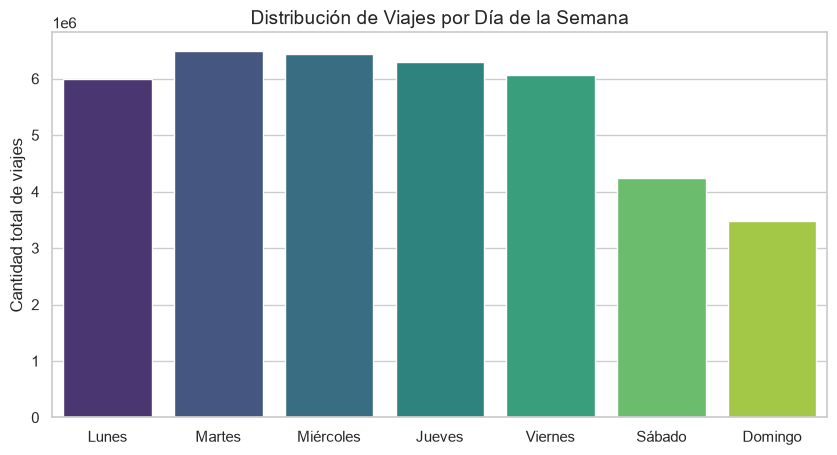

In [6]:
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
viajes_por_dia = df.groupby('dia_semana').size()

plt.figure(figsize=(10, 5))
sns.barplot(x=dias, y=viajes_por_dia.values, palette='viridis')
plt.title('Distribución de Viajes por Día de la Semana', fontsize=14)
plt.ylabel('Cantidad total de viajes', fontsize=12)
plt.show()

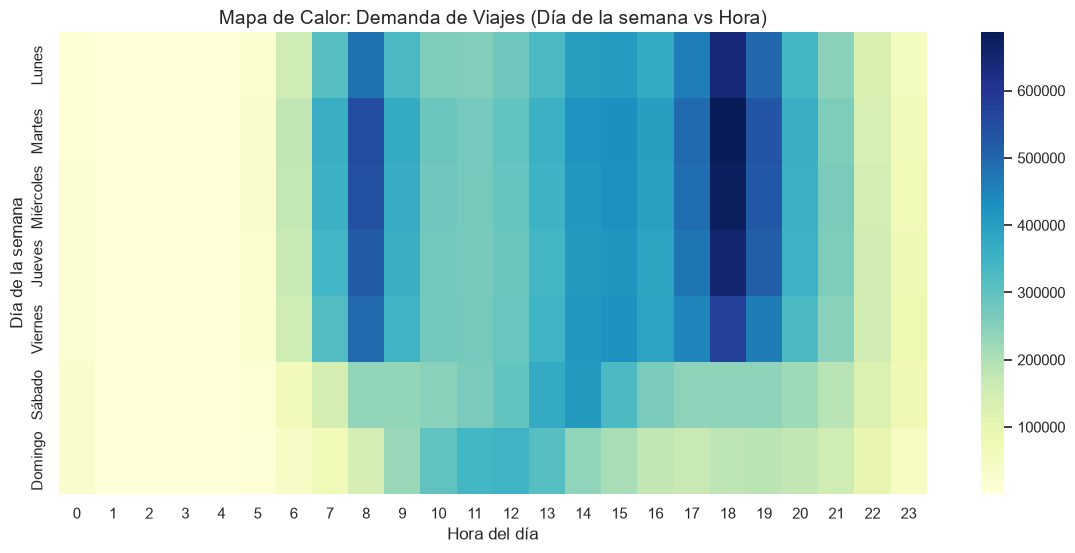

In [7]:
# Crear una tabla cruzada de día vs hora
heatmap_data = pd.crosstab(df['dia_semana'], df['hora'])
heatmap_data.index = dias

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False)
plt.title('Mapa de Calor: Demanda de Viajes (Día de la semana vs Hora)', fontsize=14)
plt.xlabel('Hora del día')
plt.ylabel('Día de la semana')
plt.show()

In [8]:
import pandas as pd

# 1. Agrupar por estación de origen, fecha (día exacto) y hora
# Extraemos la fecha sin la hora para poder agrupar
df['fecha'] = df['inicio_del_viaje'].dt.date

print("Agrupando viajes por estación, fecha y hora...")
df_grouped = df.groupby(['origen_id', 'fecha', 'hora']).size().reset_index(name='demanda')

# 2. Volver a extraer variables temporales en el dataset agrupado
df_grouped['fecha'] = pd.to_datetime(df_grouped['fecha'])
df_grouped['dia_semana'] = df_grouped['fecha'].dt.dayofweek
df_grouped['mes'] = df_grouped['fecha'].dt.month
df_grouped['es_fin_de_semana'] = df_grouped['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

# 3. Ordenar y revisar el dataset final procesado
df_grouped = df_grouped.sort_values(by=['fecha', 'hora', 'origen_id'])
print(f"Dataset procesado listo. Tamaño final: {df_grouped.shape}")
df_grouped.head(10)

Agrupando viajes por estación, fecha y hora...


C:\Users\alejandro.ojedaz\AppData\Local\Temp\ipykernel_42476\3650005564.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_grouped['dia_semana'] = df_grouped['fecha'].dt.dayofweek


Dataset procesado listo. Tamaño final: (12775515, 7)


,origen_id,fecha,hora,demanda,dia_semana,mes,es_fin_de_semana
4490108,79,2014-12-01,9,11,0,12,0
640675,14,2014-12-01,11,11,0,12,0
283909,8,2014-12-01,12,2,0,12,0
334345,9,2014-12-01,12,1,0,12,0
1042953,21,2014-12-01,12,2,0,12,0
1366199,27,2014-12-01,12,1,0,12,0
1657165,32,2014-12-01,12,1,0,12,0
1783970,34,2014-12-01,12,6,0,12,0
1846431,35,2014-12-01,12,5,0,12,0
2326817,43,2014-12-01,12,1,0,12,0
